# ⚽ Can We Play Football Outside? — KNN Weather Classifier

## Project Overview
Our project predicts **whether a person can go outside and play football** based on weather conditions.

| Item | Value |
|---|---|
| **Input features** | `Temperature`, `Humidity`, `Rain` |
| **Target variable** | `Play_Outside` (Yes / No) |
| **Algorithm** | K-Nearest Neighbors (KNN), **K = 3** |
| **Evaluation** | Accuracy |

### Steps
1. Load and explore the dataset
2. Create the target variable `Play_Outside`
3. Preprocessing (missing values, encoding)
4. Split the data into training and testing sets
5. Feature scaling
6. Train KNN with K = 3
7. Evaluate with accuracy
8. Predict for a new weather condition

## 1. Import Libraries
- **pandas**: read and handle the table of data
- **matplotlib / seaborn**: draw charts
- **scikit-learn**: split the data, scale it, build the KNN model, and measure accuracy

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_style("whitegrid")

## 2. Load the Dataset
The file `weather_forecast_data.csv` contains 2,500 weather observations.

In [2]:
df = pd.read_csv("weather_forecast_data.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (2500, 6)


,Temperature,Humidity,Wind_Speed,Cloud_Cover,Pressure,Rain
0,23.720338,89.592641,7.335604,50.501694,1032.378759,rain
1,27.879734,46.489704,5.952484,4.990053,992.614190,no rain
2,25.069084,83.072843,1.371992,14.855784,1007.231620,no rain
3,23.622080,74.367758,7.050551,67.255282,982.632013,rain
4,20.591370,96.858822,4.643921,47.676444,980.825142,no rain


In [3]:
# Basic information: column types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  2500 non-null   float64
 1   Humidity     2500 non-null   float64
 2   Wind_Speed   2500 non-null   float64
 3   Cloud_Cover  2500 non-null   float64
 4   Pressure     2500 non-null   float64
 5   Rain         2500 non-null   str    
dtypes: float64(5), str(1)
memory usage: 133.5 KB


In [4]:
# Summary statistics (min, max, mean, ...) of the numeric columns
df.describe()

,Temperature,Humidity,Wind_Speed,Cloud_Cover,Pressure
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,22.581725,64.347094,9.906255,49.658104,1014.312336
std,7.326996,19.954739,5.780316,29.123104,20.196433
min,10.001842,30.005071,0.009819,0.015038,980.014486
25%,16.359398,47.339815,4.761909,23.900016,996.938630
50%,22.536448,63.920797,9.908572,49.488284,1013.433035
75%,28.976476,81.561021,14.948408,75.324140,1031.735067
max,34.995214,99.997481,19.999132,99.997795,1049.985593


## 3. Keep Only the Features We Need
The dataset has extra columns (Wind_Speed, Cloud_Cover, Pressure).  
Our project only uses **Temperature, Humidity and Rain**, so we keep those three.

In [5]:
df = df[["Temperature", "Humidity", "Rain"]].copy()
df.head()

,Temperature,Humidity,Rain
0,23.720338,89.592641,rain
1,27.879734,46.489704,no rain
2,25.069084,83.072843,no rain
3,23.622080,74.367758,rain
4,20.591370,96.858822,no rain


## 4. Preprocessing

### 4.1 Check for missing values
Missing values can break the model, so we check and remove them if any exist.

In [6]:
print("Missing values per column:")
print(df.isnull().sum())

df = df.dropna()
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Rows after cleaning:", len(df))

Missing values per column:
Temperature    0
Humidity       0
Rain           0
dtype: int64

Duplicate rows: 0
Rows after cleaning: 2500


### 4.2 Encode `Rain` as a number
KNN measures **distance** between points, so every feature must be a number.  
- `"rain"` → **1**
- `"no rain"` → **0**

In [7]:
df["Rain"] = df["Rain"].map({"rain": 1, "no rain": 0})
df["Rain"].value_counts()

Rain
0    2186
1     314
Name: count, dtype: int64

## 5. Create the Target Variable `Play_Outside`
The dataset does not include a `Play_Outside` column, so we create it with a simple, common-sense rule.  
It is a **good day to play football** (`1 = Yes`) when **all** of these are true:

| Condition | Reason |
|---|---|
| No rain (`Rain == 0`) | Wet, slippery field |
| 15 °C ≤ Temperature ≤ 32 °C | Not too cold, not too hot |
| Humidity ≤ 85 % | Very humid air makes running exhausting |

Otherwise → `0 = No`.

In [8]:
df["Play_Outside"] = (
    (df["Rain"] == 0)
    & (df["Temperature"].between(15, 32))
    & (df["Humidity"] <= 85)
).astype(int)

print(df["Play_Outside"].value_counts().rename({1: "Yes (1)", 0: "No (0)"}))
df.head(10)

Play_Outside
No (0)     1260
Yes (1)    1240
Name: count, dtype: int64


,Temperature,Humidity,Rain,Play_Outside
0,23.720338,89.592641,1,0
1,27.879734,46.489704,0,1
2,25.069084,83.072843,0,1
3,23.622080,74.367758,1,0
4,20.591370,96.858822,0,0
5,26.147353,48.217260,0,1
6,20.939680,40.799444,0,1
7,32.294325,51.848471,0,0
8,34.091569,48.057114,0,0
9,19.586038,82.978293,1,0


## 6. Visualize the Data
Charts help us see how each feature relates to the decision.

C:\Users\user\AppData\Local\Temp\ipykernel_20620\3564513582.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Play_Outside", data=df, ax=axes[0], palette=["#d9534f", "#5cb85c"])


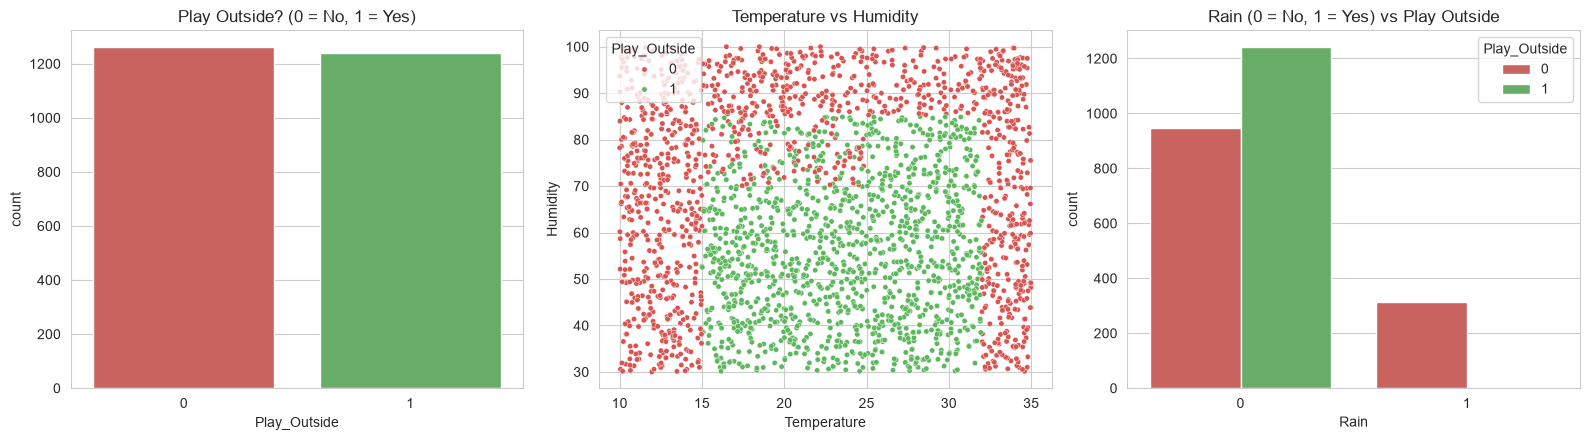

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Class balance
sns.countplot(x="Play_Outside", data=df, ax=axes[0], palette=["#d9534f", "#5cb85c"])
axes[0].set_title("Play Outside? (0 = No, 1 = Yes)")

# Temperature vs Humidity, colored by target
sns.scatterplot(x="Temperature", y="Humidity", hue="Play_Outside", data=df,
                ax=axes[1], palette=["#d9534f", "#5cb85c"], s=15)
axes[1].set_title("Temperature vs Humidity")

# Rain vs target
sns.countplot(x="Rain", hue="Play_Outside", data=df, ax=axes[2], palette=["#d9534f", "#5cb85c"])
axes[2].set_title("Rain (0 = No, 1 = Yes) vs Play Outside")

plt.tight_layout()
plt.show()

**What we see:**
- When it rains, the answer is always **No**.
- The green (Yes) points sit in the middle temperature range and lower humidity area.

## 7. Split Features (X) and Target (y)
- **X** = the inputs the model looks at
- **y** = the answer the model should learn to predict

In [10]:
X = df[["Temperature", "Humidity", "Rain"]]
y = df["Play_Outside"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2500, 3)
y shape: (2500,)


## 8. Train / Test Split
We divide the data:
- **80 % training data** → the model learns from it
- **20 % testing data** → hidden from the model, used to check how well it learned

`stratify=y` keeps the same Yes/No ratio in both parts. `random_state=42` makes the result repeatable.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

Training samples: 2000
Testing samples : 500


## 9. Feature Scaling
KNN uses **distance**. Without scaling, big numbers dominate:
- Humidity ranges 30 – 100
- Rain is only 0 or 1

`StandardScaler` converts every feature to the same scale (mean 0, standard deviation 1) so each feature counts fairly.

⚠️ We **fit** the scaler on the training data only, then apply it to the test data. This prevents information from the test set leaking into training.

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame(X_train_scaled, columns=X.columns).describe().round(2)

,Temperature,Humidity,Rain
count,2000.00,2000.00,2000.00
mean,0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-1.72,-1.72,-0.37
25%,-0.84,-0.86,-0.37
50%,-0.02,-0.03,-0.37
75%,0.88,0.87,-0.37
max,1.70,1.80,2.67


## 10. Train the KNN Model (K = 3)
### How KNN works
1. A new weather condition arrives.
2. The model measures the distance from it to **every** training observation.
3. It picks the **3 nearest** observations (K = 3).
4. It looks at their answers and uses **majority voting**: if 2 or 3 of them say *Yes*, the prediction is *Yes*.

KNN does not really "train"; it just **stores** the training data and compares new points to it.

In [13]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)
print("KNN model with K = 3 is ready.")

KNN model with K = 3 is ready.


## 11. Evaluate the Model — Accuracy
**Accuracy** = (number of correct predictions) ÷ (total predictions).

In [14]:
y_pred = knn.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}  ({accuracy * 100:.2f} %)")
print(f"Correct predictions: {(y_pred == y_test).sum()} out of {len(y_test)}")

Accuracy: 0.9920  (99.20 %)
Correct predictions: 496 out of 500


### Confusion Matrix
Shows where the model is right and where it makes mistakes:
- **Diagonal** boxes = correct predictions
- **Off-diagonal** boxes = mistakes

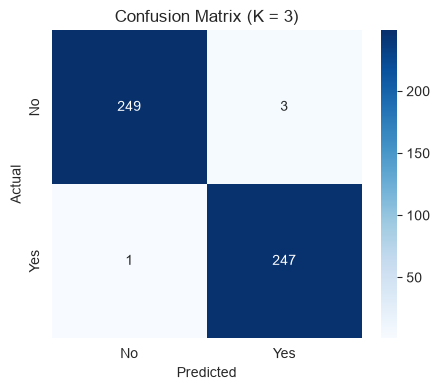

              precision    recall  f1-score   support

          No       1.00      0.99      0.99       252
         Yes       0.99      1.00      0.99       248

    accuracy                           0.99       500
   macro avg       0.99      0.99      0.99       500
weighted avg       0.99      0.99      0.99       500



In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (K = 3)")
plt.show()

print(classification_report(y_test, y_pred, target_names=["No", "Yes"]))

## 12. (Extra) Why K = 3? Comparing Different K Values
We test K from 1 to 20 to see how accuracy changes. Odd values of K avoid ties in a Yes/No vote.

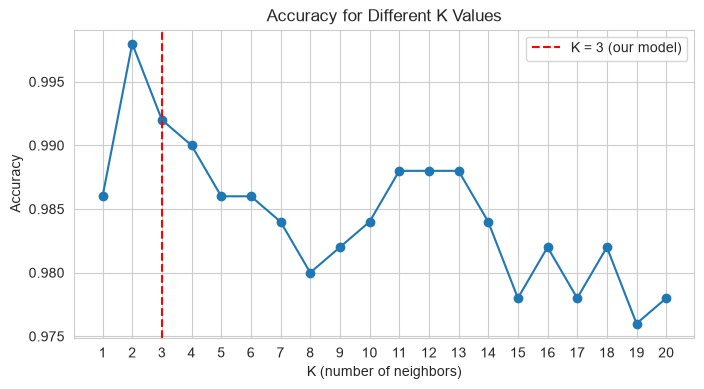

In [16]:
k_values = range(1, 21)
scores = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    scores.append(accuracy_score(y_test, model.predict(X_test_scaled)))

plt.figure(figsize=(8, 4))
plt.plot(k_values, scores, marker="o")
plt.axvline(3, color="red", linestyle="--", label="K = 3 (our model)")
plt.xlabel("K (number of neighbors)")
plt.ylabel("Accuracy")
plt.title("Accuracy for Different K Values")
plt.xticks(k_values)
plt.legend()
plt.show()

## 13. Predict for a New Weather Condition
We give the model a new day's weather. It:
1. scales the input with the **same** scaler,
2. finds the **3 nearest** weather observations,
3. uses **majority voting** to decide.

In [17]:
def can_play_outside(temperature, humidity, rain):
    """rain: 1 = raining, 0 = not raining"""
    new_day = pd.DataFrame([[temperature, humidity, rain]],
                           columns=["Temperature", "Humidity", "Rain"])
    new_day_scaled = scaler.transform(new_day)

    # Find the 3 nearest neighbors
    distances, indices = knn.kneighbors(new_day_scaled)
    neighbors = X_train.iloc[indices[0]].copy()
    neighbors["Play_Outside"] = y_train.iloc[indices[0]].values
    neighbors["Distance"] = distances[0].round(3)

    prediction = knn.predict(new_day_scaled)[0]
    yes_votes = neighbors["Play_Outside"].sum()

    print(f"New weather -> Temperature: {temperature} °C | Humidity: {humidity} % | Rain: {'Yes' if rain else 'No'}")
    print("\nThe 3 nearest weather observations:")
    display(neighbors)
    print(f"Votes -> Yes: {yes_votes}, No: {3 - yes_votes}")
    print("Prediction:", "✅ YES, go play football!" if prediction == 1 else "❌ NO, better stay inside.")
    print("-" * 60)


can_play_outside(temperature=24, humidity=55, rain=0)   # nice day
can_play_outside(temperature=22, humidity=70, rain=1)   # raining
can_play_outside(temperature=34, humidity=60, rain=0)   # too hot

New weather -> Temperature: 24 °C | Humidity: 55 % | Rain: No

The 3 nearest weather observations:


,Temperature,Humidity,Rain,Play_Outside,Distance
2447,23.989263,55.291003,0,1,0.015
50,24.254919,54.724964,0,1,0.038
2454,24.414877,54.335622,0,1,0.066


Votes -> Yes: 3, No: 0
Prediction: ✅ YES, go play football!
------------------------------------------------------------
New weather -> Temperature: 22 °C | Humidity: 70 % | Rain: Yes

The 3 nearest weather observations:


,Temperature,Humidity,Rain,Play_Outside,Distance
1829,22.087516,71.530065,1,0,0.078
1064,22.780545,70.271469,1,0,0.108
2018,21.871793,73.037066,1,0,0.154


Votes -> Yes: 0, No: 3
Prediction: ❌ NO, better stay inside.
------------------------------------------------------------
New weather -> Temperature: 34 °C | Humidity: 60 % | Rain: No

The 3 nearest weather observations:


,Temperature,Humidity,Rain,Play_Outside,Distance
1868,33.876604,59.590553,0,0,0.027
1645,34.013060,58.981077,0,0,0.051
164,34.388038,59.372025,0,0,0.062


Votes -> Yes: 0, No: 3
Prediction: ❌ NO, better stay inside.
------------------------------------------------------------


## 14. Conclusion
- We built a model that predicts **whether a person can play football outside** using **Temperature, Humidity and Rain**.
- We cleaned the data, encoded `Rain` as 0/1, created the `Play_Outside` target, and split the data into **80 % training / 20 % testing**.
- We used **feature scaling** so every feature has an equal say in the distance.
- **KNN with K = 3** predicts a new day by finding the 3 most similar past days and using **majority voting**.
- The model was evaluated with **accuracy** (see section 11), along with a confusion matrix for more detail.

**Limitation:** `Play_Outside` was created from a rule, not collected from real people. With real survey data, the model could learn people's actual preferences.